In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split    
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from warnings import filterwarnings
filterwarnings('ignore')

In [ ]:
data = pd.read_csv('spam.csv', encoding='latin-1')
data.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [9]:
data.drop(['Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], axis=1, inplace=True)
data.head()

,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [ ]:
data.rename(columns={'v1': 'label', 'v2': 'text'}, inplace=True)
data.head()

,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [11]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

In [14]:
data['Target'] = le.fit_transform(data['label'])
data.head()

,label,text,Target
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


In [15]:
data.isnull().sum()

label     0
text      0
Target    0
dtype: int64

In [16]:
data.duplicated().sum()

np.int64(403)

In [17]:
data = data.drop_duplicates(keep='first')
data.duplicated().sum()

np.int64(0)

In [18]:
data.shape

(5169, 3)

In [20]:
data.head()

,label,text,Target
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


In [21]:
data['Target'].value_counts()

Target
0    4516
1     653
Name: count, dtype: int64

#PIE PLOT

Text(0.5, 1.0, 'Distribution of Ham and Spam Emails')

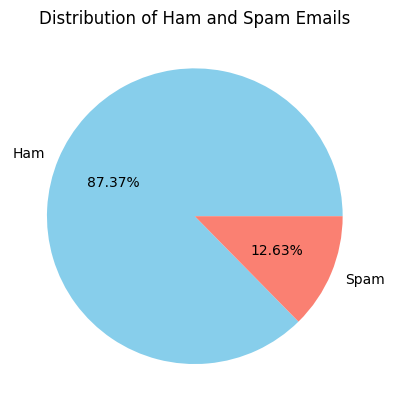

In [28]:
plt.pie(data['Target'].value_counts(), labels=['Ham', 'Spam'], autopct='%0.2f%%', colors=['skyblue', 'salmon'])
plt.title('Distribution of Ham and Spam Emails')    

In [ ]:
import nltk
nltk.download('punkt')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


True

In [37]:
data['Char_Count'] = data['text'].apply(len)
data.head()

,label,text,Target,Char_Count
0,ham,"Go until jurong point, crazy.. Available only ...",0,111
1,ham,Ok lar... Joking wif u oni...,0,29
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1,155
3,ham,U dun say so early hor... U c already then say...,0,49
4,ham,"Nah I don't think he goes to usf, he lives aro...",0,61


In [40]:
data['words_count'] = data['text'].apply(lambda x: len(str(x).split()))
data.head()

,label,text,Target,Char_Count,words_count
0,ham,"Go until jurong point, crazy.. Available only ...",0,111,20
1,ham,Ok lar... Joking wif u oni...,0,29,6
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1,155,28
3,ham,U dun say so early hor... U c already then say...,0,49,11
4,ham,"Nah I don't think he goes to usf, he lives aro...",0,61,13


In [42]:
data['Sentence_Count'] = data['text'].apply(lambda x: len(str(x).split('.')))
data.head()

,label,text,Target,Char_Count,words_count,Sentence_Count
0,ham,"Go until jurong point, crazy.. Available only ...",0,111,20,9
1,ham,Ok lar... Joking wif u oni...,0,29,6,7
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1,155,28,2
3,ham,U dun say so early hor... U c already then say...,0,49,11,7
4,ham,"Nah I don't think he goes to usf, he lives aro...",0,61,13,1


In [43]:
data[['Char_Count', 'words_count', 'Sentence_Count']].describe()

,Char_Count,words_count,Sentence_Count
count,5169.000000,5169.000000,5169.000000
mean,78.977945,15.340685,2.934030
std,58.236293,11.068488,2.541852
min,2.000000,1.000000,1.000000
25%,36.000000,7.000000,1.000000
50%,60.000000,12.000000,2.000000
75%,117.000000,22.000000,4.000000
max,910.000000,171.000000,42.000000


#PAIRPLOT

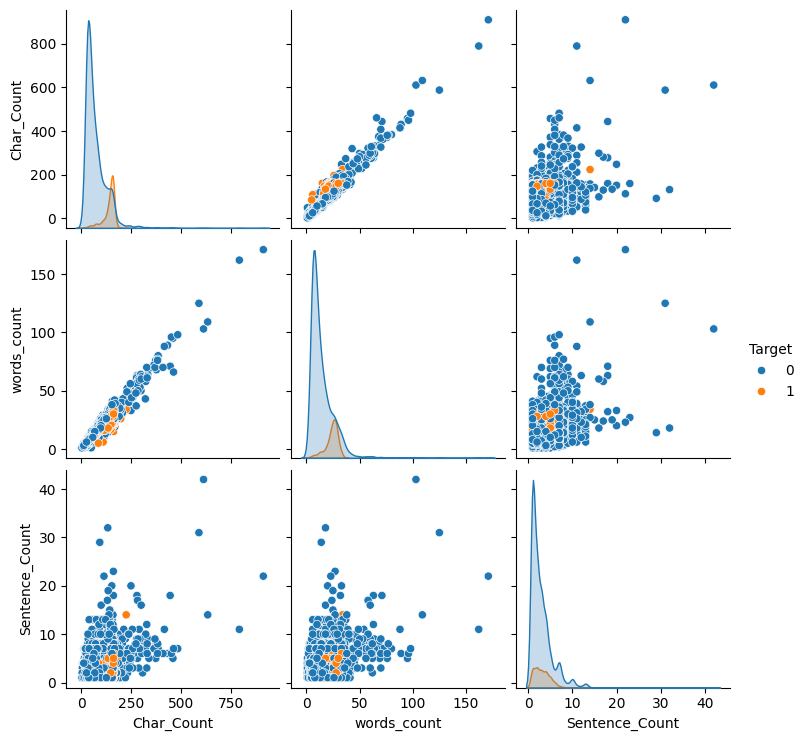

In [44]:
sns.pairplot(data[['Char_Count', 'words_count', 'Sentence_Count', 'Target']], hue='Target')

#DATA PREPROCESSING


In [46]:
import string
from nltk.stem import PorterStemmer
ps = PorterStemmer()

In [47]:
def trans_text(text):
    text = text.lower()
    text = nltk.word_tokenize(text)
    
    y = []
    for i in text:
        if i.isalnum():
            y.append(i)
    
    text = y[:]
    y.clear()
    
    for i in text:
        if i not in string.punctuation:
            y.append(i)
            
    text = y[:]
    y.clear()
    
    for i in text:
        y.append(ps.stem(i))
    
    return " ".join(y)

In [48]:
string.punctuation

'!"#$%&\'()*+,-./:;<=>?@[\\]^_`{|}~'

In [58]:
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize 

def trans_text(text):
    return str(text).lower()
    

In [59]:
data['Transformed_Text'] = data['text'].apply(trans_text)  

#Transformation of data to matrix

In [60]:
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(max_features=3000)

In [61]:
X= tfidf.fit_transform(data['Transformed_Text']).toarray()
X

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(5169, 3000))

In [62]:
X.shape

(5169, 3000)

In [63]:
Y = data['Target'].values
Y

array([0, 0, 1, ..., 0, 0, 0], shape=(5169,))

#Splitting Data

#

In [64]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=2)

#MODEL BUILDING

In [65]:
from sklearn.naive_bayes import MultinomialNB, GaussianNB, BernoulliNB
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score
MNB = MultinomialNB()
GNB = GaussianNB()
BNB = BernoulliNB()

#Model 1 Confusion Matrix

In [66]:
MNB.fit(X_train, Y_train)
Y_pred_mnb = MNB.predict(X_test)
print("accuracy_score is:", accuracy_score(Y_test, Y_pred_mnb)*100)
print("confusion_matrix is:\n", confusion_matrix(Y_test, Y_pred_mnb))

accuracy_score is: 97.29206963249516
confusion_matrix is:
 [[896   0]
 [ 28 110]]


In [67]:
BNB.fit(X_train, Y_train)
Y_pred_bnb = BNB.predict(X_test)
print("accuracy_score is:", accuracy_score(Y_test, Y_pred_bnb)*100) 
print("confusion_matrix is:\n", confusion_matrix(Y_test, Y_pred_bnb))

accuracy_score is: 98.45261121856866
confusion_matrix is:
 [[893   3]
 [ 13 125]]


In [68]:
GNB.fit(X_train, Y_train)
Y_pred_gnb = GNB.predict(X_test)    
print("accuracy_score is:", accuracy_score(Y_test, Y_pred_gnb)*100)
print("confusion_matrix is:\n", confusion_matrix(Y_test, Y_pred_gnb))

accuracy_score is: 89.84526112185686
confusion_matrix is:
 [[812  84]
 [ 21 117]]


In [69]:
results = pd.DataFrame({
    'Model Tests Score': ['confusion_matrix 1', 'confusion_matrix 2', 'confusion_matrix 3'],
    'Score': [97.29, 98.45, 89.84]})
    
result_data = results.sort_values(by='Score', ascending=False)
result_data = result_data.set_index('Score')
result_data.head(9)


,Model Tests Score
Score,
98.45,confusion_matrix 2
97.29,confusion_matrix 1
89.84,confusion_matrix 3
